In [1]:
import matplotlib.pyplot as plt
import numpy as np


def plot_selection_result(results, ax, budget=None, label=None, color=None):
    import scipy.stats as sps

    if budget is None:
        budget = results.shape[-1]

    def ci(y):
        br = sps.bootstrap((y,), np.mean, vectorized=True)
        ci_l = br.confidence_interval.low
        ci_u = br.confidence_interval.high
        return ci_l, ci_u

    iters = np.arange(0, budget, 1)
    agg_value = results.mean(axis=0)[:budget].ravel()
    _ci_lb, _ci_ub = ci(results)[:budget]

    line, *_ = ax.plot(iters, agg_value, linewidth=1.5, label=label, color=color)

    ax.plot(iters, _ci_lb, linewidth=1.5, alpha=0.5, color=line.get_color())
    ax.plot(iters, _ci_ub, linewidth=1.5, alpha=0.5, color=line.get_color())
    ax.fill_between(iters, _ci_lb, _ci_ub, alpha=0.3, color=line.get_color())


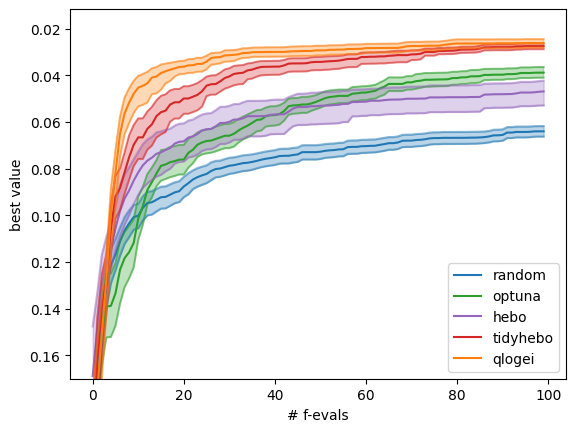

In [9]:
import numpy as np
import torch

# random res
random_out = np.loadtxt("random/random_out.txt")
random_out = random_out.reshape(-1, 100)
random_res = torch.from_numpy(random_out).cummin(axis=1).values.detach().numpy()

# optuna 
optuna_out = np.loadtxt("optuna/optuna_values.txt")
optuna_res = torch.from_numpy(optuna_out).cummin(axis=1).values.detach().numpy()

# hebo
hebo_out = np.loadtxt("hebo/hebo_values.txt")
hebo_res = torch.from_numpy(hebo_out).cummin(axis=1).values.detach().numpy()

# tidyhebo
tidyhebo_out = np.loadtxt("tidyhebo/tidyhebo_values.txt")
tidyhebo_res = torch.from_numpy(tidyhebo_out).cummin(axis=1).values.detach().numpy()

# qlogei
qlogei_out = np.loadtxt("qlogei/qlogei_values.txt")
qlogei_res = torch.from_numpy(qlogei_out).cummin(axis=1).values.detach().numpy()


import matplotlib.pyplot as plt

ax = plt.gca()


tr = lambda x: x

plot_selection_result(tr(random_res), ax, budget=100, label="random", color="tab:blue")
plot_selection_result(tr(optuna_res), ax, budget=100, label="optuna", color="tab:green")
plot_selection_result(tr(hebo_res), ax, budget=100, label="hebo", color="tab:purple")
plot_selection_result(tr(tidyhebo_res), ax, budget=100, label="tidyhebo", color="tab:red")
plot_selection_result(tr(qlogei_res), ax, budget=100, label="qlogei", color="tab:orange")

ax.invert_yaxis()

ax.set_ylim(bottom=0.17)

ax.set_ylabel("best value")
ax.set_xlabel("# f-evals")

ax.legend()